In [2]:
!pip install xgboost

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

from xgboost import XGBRegressor

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import pandas as pd
import numpy as np

np.random.seed(42)

# Regions
regions = [
    "Chennai",
    "Coimbatore",
    "Madurai",
    "Trichy"
]

# One year of hourly data
dates = pd.date_range(
    start="2025-01-01",
    end="2025-12-31 23:00",
    freq="h"
)

data = []

# Base electricity demand for each region
base_demand = {
    "Chennai": 4500,
    "Coimbatore": 3000,
    "Madurai": 2500,
    "Trichy": 2200
}

# Holidays
holiday_dates = [
    "2025-01-01",
    "2025-01-14",
    "2025-01-15",
    "2025-01-26",
    "2025-05-01",
    "2025-08-15",
    "2025-10-02",
    "2025-12-25"
]

for region in regions:

    for dt in dates:

        hour = dt.hour
        month = dt.month
        day_of_week = dt.day_name()

        # -------------------------
        # Temperature
        # -------------------------

        monthly_temperature = {
            1: 25,
            2: 27,
            3: 29,
            4: 31,
            5: 33,
            6: 32,
            7: 31,
            8: 30,
            9: 30,
            10: 29,
            11: 27,
            12: 25
        }

        temperature = (
            monthly_temperature[month]
            + 4 * np.sin((hour - 6) * np.pi / 12)
            + np.random.normal(0, 1.5)
        )

        # -------------------------
        # Humidity
        # -------------------------

        humidity = (
            70
            - 0.5 * (temperature - 25)
            + np.random.normal(0, 5)
        )

        humidity = np.clip(
            humidity,
            35,
            95
        )

        # -------------------------
        # Holiday
        # -------------------------

        holiday = int(
            dt.strftime("%Y-%m-%d")
            in holiday_dates
        )

        # -------------------------
        # Weekend
        # -------------------------

        weekend = dt.weekday() >= 5

        # -------------------------
        # Morning peak
        # -------------------------

        morning_peak = (
            500
            * np.exp(-((hour - 9) / 3) ** 2)
        )

        # -------------------------
        # Evening peak
        # -------------------------

        evening_peak = (
            1000
            * np.exp(-((hour - 19) / 3) ** 2)
        )

        # -------------------------
        # Night reduction
        # -------------------------

        night_reduction = -500 if hour < 5 else 0

        # -------------------------
        # Weekend effect
        # -------------------------

        weekend_effect = -300 if weekend else 0

        # -------------------------
        # Holiday effect
        # -------------------------

        holiday_effect = -400 if holiday else 0

        # -------------------------
        # Temperature effect
        # -------------------------

        temperature_effect = (
            80 * max(temperature - 28, 0)
            + 50 * max(20 - temperature, 0)
        )

        # -------------------------
        # Random variation
        # -------------------------

        random_noise = np.random.normal(0, 150)

        # -------------------------
        # Electricity demand
        # -------------------------

        demand = (
            base_demand[region]
            + morning_peak
            + evening_peak
            + night_reduction
            + weekend_effect
            + holiday_effect
            + temperature_effect
            + random_noise
        )

        demand = max(demand, 500)

        data.append([
            dt,
            region,
            round(demand, 2),
            round(temperature, 2),
            round(humidity, 2),
            holiday,
            day_of_week
        ])

# Create DataFrame
df = pd.DataFrame(
    data,
    columns=[
        "Date_Time",
        "Region",
        "Electricity_Demand",
        "Temperature",
        "Humidity",
        "Holiday",
        "Day_of_Week"
    ]
)

print("Dataset created successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Dataset created successfully!
Rows: 35040
Columns: 7


In [5]:
df.head()

,Date_Time,Region,Electricity_Demand,Temperature,Humidity,Holiday,Day_of_Week
0,2025-01-01 00:00:00,Chennai,3697.21,21.75,70.94,1,Wednesday
1,2025-01-01 01:00:00,Chennai,3565.29,23.42,69.62,1,Wednesday
2,2025-01-01 02:00:00,Chennai,3531.74,23.90,74.38,1,Wednesday
3,2025-01-01 03:00:00,Chennai,3539.30,22.99,68.69,1,Wednesday
4,2025-01-01 04:00:00,Chennai,3372.35,23.36,61.25,1,Wednesday


In [6]:
df.shape

(35040, 7)

In [7]:
df.columns

Index(['Date_Time', 'Region', 'Electricity_Demand', 'Temperature', 'Humidity',
       'Holiday', 'Day_of_Week'],
      dtype='object')

In [8]:
df.to_csv(
    "Energy_Electricity_Demand.csv",
    index=False
)

print("CSV file created successfully!")

CSV file created successfully!


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date_Time           35040 non-null  datetime64[ns]
 1   Region              35040 non-null  object        
 2   Electricity_Demand  35040 non-null  float64       
 3   Temperature         35040 non-null  float64       
 4   Humidity            35040 non-null  float64       
 5   Holiday             35040 non-null  int64         
 6   Day_of_Week         35040 non-null  object        
dtypes: datetime64[ns](1), float64(3), int64(1), object(2)
memory usage: 1.9+ MB


In [10]:
df.isnull().sum()

,0
Date_Time,0
Region,0
Electricity_Demand,0
Temperature,0
Humidity,0
Holiday,0
Day_of_Week,0


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe()

,Date_Time,Electricity_Demand,Temperature,Humidity,Holiday
count,35040,35040.000000,35040.000000,35040.000000,35040.000000
mean,2025-07-02 11:30:00,3362.085188,29.081684,67.960668,0.021918
min,2025-01-01 00:00:00,926.240000,16.490000,45.480000,0.000000
25%,2025-04-02 05:45:00,2621.422500,26.260000,64.300000,0.000000
50%,2025-07-02 11:30:00,3204.950000,29.090000,67.960000,0.000000
75%,2025-10-01 17:15:00,3972.565000,32.070000,71.610000,0.000000
max,2025-12-31 23:00:00,6238.550000,41.230000,88.290000,1.000000
std,NaN,1048.895451,4.057673,5.391445,0.146417


In [13]:
df["Date_Time"] = pd.to_datetime(
    df["Date_Time"]
)

df["Hour"] = df["Date_Time"].dt.hour

df["Day"] = df["Date_Time"].dt.day

df["Month"] = df["Date_Time"].dt.month

df["Year"] = df["Date_Time"].dt.year

df["Is_Weekend"] = (
    df["Date_Time"].dt.dayofweek >= 5
).astype(int)

In [14]:
df.head()

,Date_Time,Region,Electricity_Demand,Temperature,Humidity,Holiday,Day_of_Week,Hour,Day,Month,Year,Is_Weekend
0,2025-01-01 00:00:00,Chennai,3697.21,21.75,70.94,1,Wednesday,0,1,1,2025,0
1,2025-01-01 01:00:00,Chennai,3565.29,23.42,69.62,1,Wednesday,1,1,1,2025,0
2,2025-01-01 02:00:00,Chennai,3531.74,23.90,74.38,1,Wednesday,2,1,1,2025,0
3,2025-01-01 03:00:00,Chennai,3539.30,22.99,68.69,1,Wednesday,3,1,1,2025,0
4,2025-01-01 04:00:00,Chennai,3372.35,23.36,61.25,1,Wednesday,4,1,1,2025,0


In [15]:
peak = df.loc[df["Electricity_Demand"].idxmax()]

print("Peak Demand Record:")
print(peak)

Peak Demand Record:
Date_Time             2025-05-07 19:00:00
Region                            Chennai
Electricity_Demand                6238.55
Temperature                         33.46
Humidity                            71.87
Holiday                                 0
Day_of_Week                     Wednesday
Hour                                   19
Day                                     7
Month                                   5
Year                                 2025
Is_Weekend                              0
Name: 3043, dtype: object


In [16]:
top10 = df.nlargest(
    10,
    "Electricity_Demand"
)

print(
    top10[
        [
            "Date_Time",
            "Region",
            "Electricity_Demand",
            "Temperature"
        ]
    ]
)

               Date_Time   Region  Electricity_Demand  Temperature
3043 2025-05-07 19:00:00  Chennai             6238.55        33.46
3209 2025-05-14 17:00:00  Chennai             6218.62        37.64
2923 2025-05-02 19:00:00  Chennai             6146.04        33.13
6283 2025-09-19 19:00:00  Chennai             6138.54        28.59
4723 2025-07-16 19:00:00  Chennai             6126.37        33.09
3763 2025-06-06 19:00:00  Chennai             6109.95        33.89
4026 2025-06-17 18:00:00  Chennai             6104.90        34.51
2419 2025-04-11 19:00:00  Chennai             6102.91        30.94
2491 2025-04-14 19:00:00  Chennai             6069.67        31.88
3330 2025-05-19 18:00:00  Chennai             6066.26        35.15


In [17]:
hourly_demand = df.groupby(
    "Hour"
)["Electricity_Demand"].mean()

print(hourly_demand)

Hour
0     2474.813103
1     2478.278288
2     2484.377082
3     2502.180842
4     2558.197164
5     3147.743158
6     3286.278048
7     3476.711130
8     3666.642562
9     3779.159411
10    3780.151507
11    3670.822390
12    3547.120658
13    3455.520753
14    3414.793918
15    3456.106726
16    3596.906596
17    3803.955418
18    4002.420753
19    4058.376041
20    3914.846795
21    3629.539966
22    3356.374918
23    3148.727274
Name: Electricity_Demand, dtype: float64


In [18]:
peak_hour = hourly_demand.idxmax()

peak_value = hourly_demand.max()

print("Peak Hour:", peak_hour)
print("Average Demand:", peak_value)

Peak Hour: 19
Average Demand: 4058.3760410958903


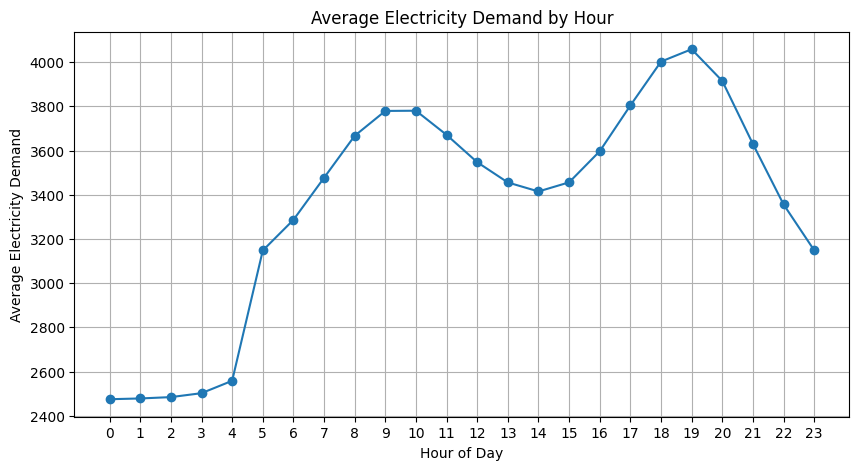

In [19]:
plt.figure(figsize=(10,5))

plt.plot(
    hourly_demand.index,
    hourly_demand.values,
    marker="o"
)

plt.title(
    "Average Electricity Demand by Hour"
)

plt.xlabel("Hour of Day")

plt.ylabel(
    "Average Electricity Demand"
)

plt.xticks(range(24))

plt.grid(True)

plt.show()

In [20]:
weekday_demand = df[
    df["Is_Weekend"] == 0
]["Electricity_Demand"].mean()

weekend_demand = df[
    df["Is_Weekend"] == 1
]["Electricity_Demand"].mean()

print("Average Weekday Demand:", weekday_demand)

print("Average Weekend Demand:", weekend_demand)

Average Weekday Demand: 3446.5690357598983
Average Weekend Demand: 3150.0632221554483


In [21]:
difference = (
    weekday_demand -
    weekend_demand
)

print(
    "Difference:",
    difference
)

Difference: 296.50581360444994


In [22]:
percentage_difference = (
    difference /
    weekday_demand
) * 100

print(
    "Percentage Difference:",
    percentage_difference,
    "%"
)

Percentage Difference: 8.602926868083943 %


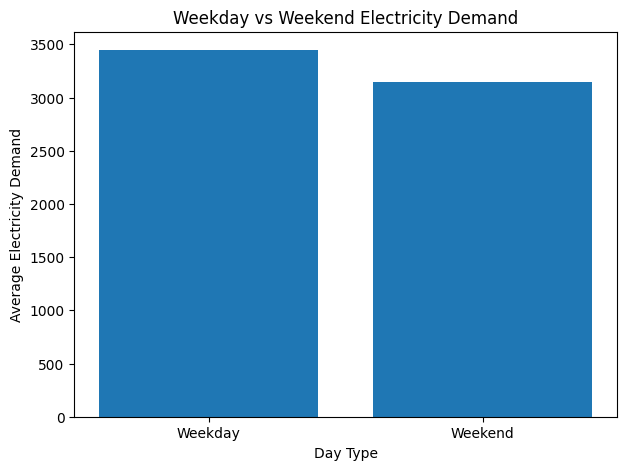

In [23]:
comparison = pd.DataFrame({
    "Day_Type": [
        "Weekday",
        "Weekend"
    ],
    "Average_Demand": [
        weekday_demand,
        weekend_demand
    ]
})

plt.figure(figsize=(7,5))

plt.bar(
    comparison["Day_Type"],
    comparison["Average_Demand"]
)

plt.title(
    "Weekday vs Weekend Electricity Demand"
)

plt.xlabel("Day Type")

plt.ylabel(
    "Average Electricity Demand"
)

plt.show()

In [24]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_pattern = df.groupby(
    "Day_of_Week"
)["Electricity_Demand"].mean()

daily_pattern = daily_pattern.reindex(
    day_order
)

print(daily_pattern)

Day_of_Week
Monday       3457.396671
Tuesday      3449.800811
Wednesday    3438.654654
Thursday     3433.747458
Friday       3453.397784
Saturday     3154.326242
Sunday       3145.800202
Name: Electricity_Demand, dtype: float64


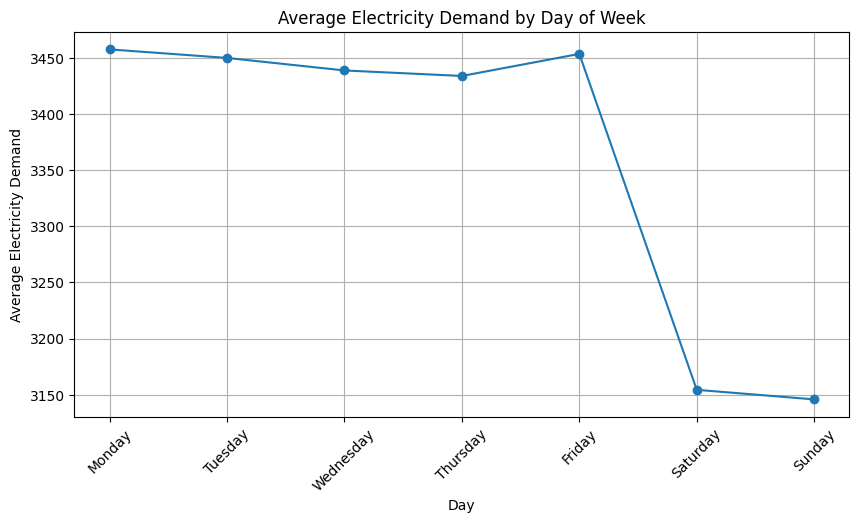

In [25]:
plt.figure(figsize=(10,5))

plt.plot(
    daily_pattern.index,
    daily_pattern.values,
    marker="o"
)

plt.title(
    "Average Electricity Demand by Day of Week"
)

plt.xlabel("Day")

plt.ylabel(
    "Average Electricity Demand"
)

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

In [26]:
temperature_correlation = df[
    [
        "Electricity_Demand",
        "Temperature"
    ]
].corr()

print(temperature_correlation)

                    Electricity_Demand  Temperature
Electricity_Demand            1.000000     0.285274
Temperature                   0.285274     1.000000


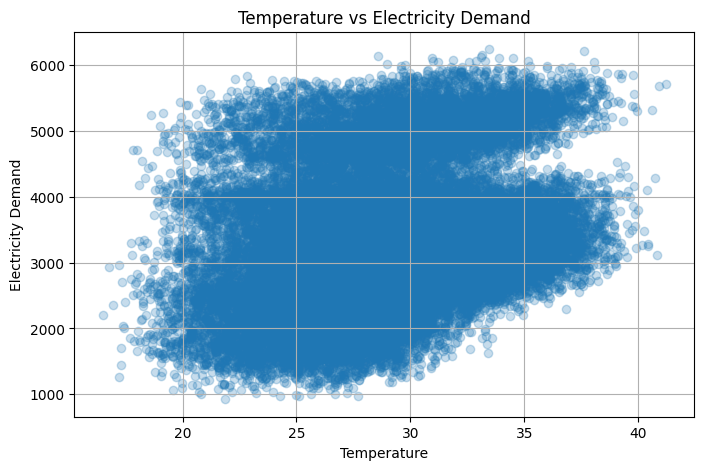

In [27]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["Temperature"],
    df["Electricity_Demand"],
    alpha=0.25
)

plt.title(
    "Temperature vs Electricity Demand"
)

plt.xlabel("Temperature")

plt.ylabel(
    "Electricity Demand"
)

plt.grid(True)

plt.show()

In [28]:
weather_corr = df[
    [
        "Electricity_Demand",
        "Temperature",
        "Humidity"
    ]
].corr()

print(weather_corr)

                    Electricity_Demand  Temperature  Humidity
Electricity_Demand            1.000000     0.285274 -0.102206
Temperature                   0.285274     1.000000 -0.377444
Humidity                     -0.102206    -0.377444  1.000000


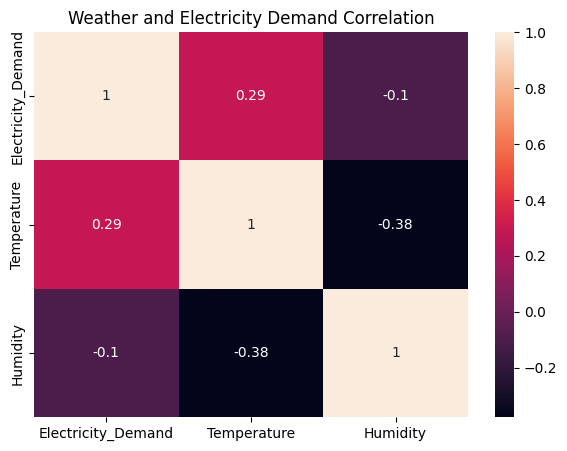

In [29]:
plt.figure(figsize=(7,5))

sns.heatmap(
    weather_corr,
    annot=True
)

plt.title(
    "Weather and Electricity Demand Correlation"
)

plt.show()

In [30]:
Q1 = df[
    "Electricity_Demand"
].quantile(0.25)

Q3 = df[
    "Electricity_Demand"
].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 2621.4224999999997
Q3: 3972.565
IQR: 1351.1425000000004


In [31]:
upper_limit = Q3 + 1.5 * IQR

print(
    "Upper Spike Limit:",
    upper_limit
)

Upper Spike Limit: 5999.27875


In [32]:
spikes = df[
    df["Electricity_Demand"]
    > upper_limit
]

print(
    "Number of unusual spikes:",
    len(spikes)
)

Number of unusual spikes: 18


In [33]:
spikes[
    [
        "Date_Time",
        "Region",
        "Electricity_Demand",
        "Temperature",
        "Humidity"
    ]
].head(20)

,Date_Time,Region,Electricity_Demand,Temperature,Humidity
2395,2025-04-10 19:00:00,Chennai,6057.85,31.00,56.68
2419,2025-04-11 19:00:00,Chennai,6102.91,30.94,64.11
2491,2025-04-14 19:00:00,Chennai,6069.67,31.88,66.09
2588,2025-04-18 20:00:00,Chennai,6040.81,31.20,66.75
2923,2025-05-02 19:00:00,Chennai,6146.04,33.13,64.06
2996,2025-05-05 20:00:00,Chennai,6057.94,33.29,63.63
3043,2025-05-07 19:00:00,Chennai,6238.55,33.46,71.87
3209,2025-05-14 17:00:00,Chennai,6218.62,37.64,59.37
3225,2025-05-15 09:00:00,Chennai,6042.86,38.06,58.34
3330,2025-05-19 18:00:00,Chennai,6066.26,35.15,65.88


In [34]:
spike_by_region = spikes.groupby(
    "Region"
).size()

print(spike_by_region)

Region
Chennai    18
dtype: int64


In [35]:
daily_demand = df.resample(
    "D",
    on="Date_Time"
)["Electricity_Demand"].sum()

print(daily_demand.head())

Date_Time
2025-01-01    278587.90
2025-01-02    316379.72
2025-01-03    318890.61
2025-01-04    288065.63
2025-01-05    291154.55
Freq: D, Name: Electricity_Demand, dtype: float64


In [36]:
peak_day = daily_demand.idxmax()

peak_day_demand = daily_demand.max()

print("Peak Day:", peak_day)

print(
    "Peak Daily Demand:",
    peak_day_demand
)

Peak Day: 2025-05-15 00:00:00
Peak Daily Demand: 356366.68


In [37]:
lowest_day = daily_demand.idxmin()

lowest_day_demand = daily_demand.min()

print("Lowest Demand Day:", lowest_day)

print(
    "Lowest Daily Demand:",
    lowest_day_demand
)

Lowest Demand Day: 2025-01-26 00:00:00
Lowest Daily Demand: 247565.74


In [38]:
weekly_demand = df.resample(
    "W",
    on="Date_Time"
)["Electricity_Demand"].sum()

print(weekly_demand.head())

Date_Time
2025-01-05    1493078.41
2025-01-12    2158218.36
2025-01-19    2081409.75
2025-01-26    2120035.41
2025-02-02    2173203.89
Freq: W-SUN, Name: Electricity_Demand, dtype: float64


In [39]:
peak_week = weekly_demand.idxmax()

peak_week_demand = weekly_demand.max()

print("Peak Week:", peak_week)

print(
    "Peak Weekly Demand:",
    peak_week_demand
)

Peak Week: 2025-05-18 00:00:00
Peak Weekly Demand: 2415217.75


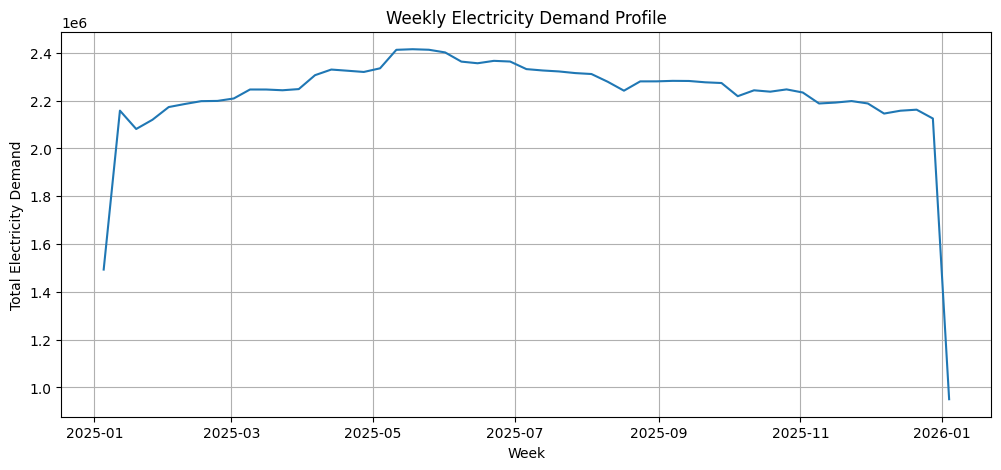

In [40]:
plt.figure(figsize=(12,5))

plt.plot(
    weekly_demand.index,
    weekly_demand.values
)

plt.title(
    "Weekly Electricity Demand Profile"
)

plt.xlabel("Week")

plt.ylabel(
    "Total Electricity Demand"
)

plt.grid(True)

plt.show()

In [42]:
regional_demand = df.groupby(
    "Region"
)["Electricity_Demand"].mean()

print(regional_demand)

Region
Chennai       4811.402872
Coimbatore    3310.700324
Madurai       2813.364298
Trichy        2512.873256
Name: Electricity_Demand, dtype: float64


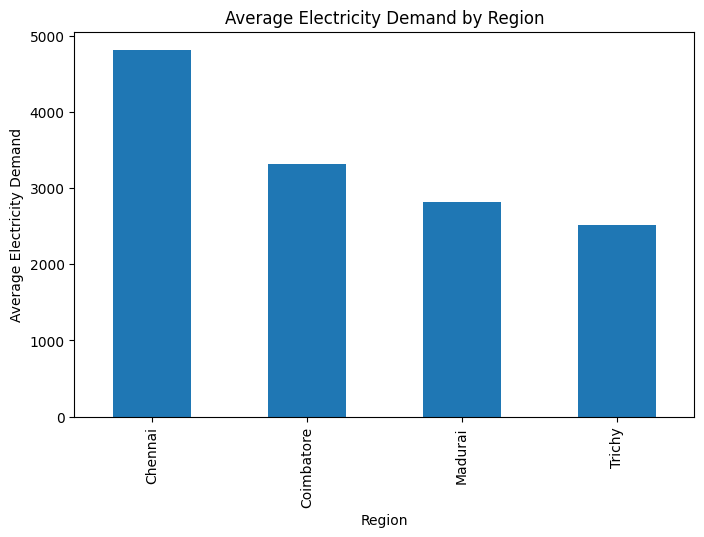

In [43]:
plt.figure(figsize=(8,5))

regional_demand.plot(
    kind="bar"
)

plt.title(
    "Average Electricity Demand by Region"
)

plt.xlabel("Region")

plt.ylabel(
    "Average Electricity Demand"
)

plt.show()

In [44]:
df.to_csv(
    "Energy_Electricity_Demand_Processed.csv",
    index=False
)

print(
    "Processed dataset saved!"
)

Processed dataset saved!


===== XGBOOST RESULTS =====
MAE  : 130.12
RMSE : 163.75
R²   : 0.9176

===== FEATURE IMPORTANCE =====
Region_Chennai       0.885911
Region_Coimbatore    0.060419
Hour                 0.027978
Is_Weekend           0.009742
Region_Madurai       0.008635
Holiday              0.003417
Temperature          0.002005
Region_Trichy        0.001219
Month                0.000440
Day                  0.000120
Humidity             0.000114
Year                 0.000000
dtype: float32


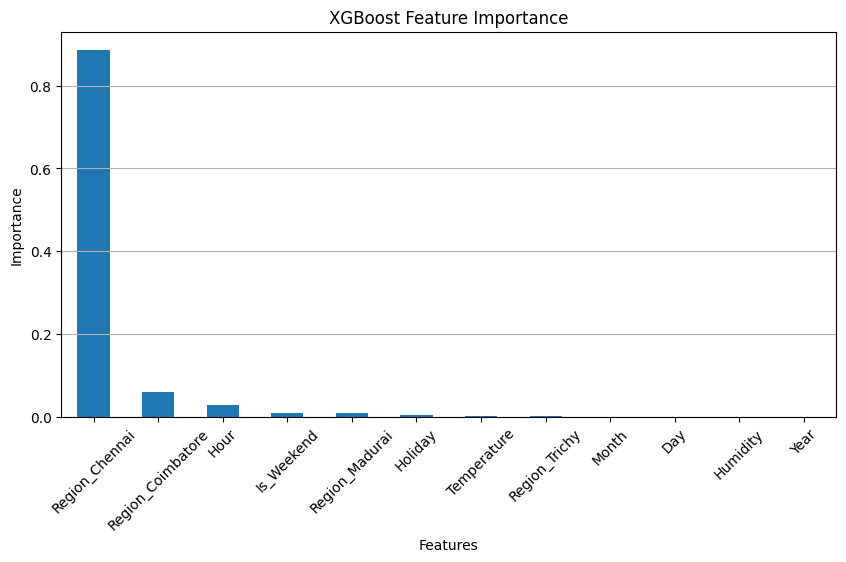

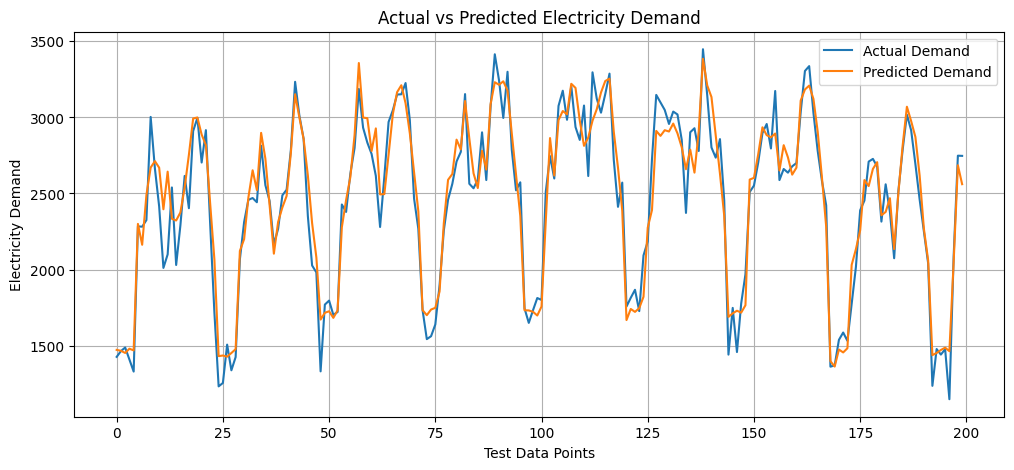

In [45]:
# ==============================
# XGBOOST MODEL
# ==============================

# Prepare data
ml_df = df.copy()

# Convert Region into numerical columns
ml_df = pd.get_dummies(
    ml_df,
    columns=["Region"],
    dtype=int
)

# Features
features = [
    "Temperature",
    "Humidity",
    "Holiday",
    "Hour",
    "Day",
    "Month",
    "Year",
    "Is_Weekend",
    "Region_Chennai",
    "Region_Coimbatore",
    "Region_Madurai",
    "Region_Trichy"
]

X = ml_df[features]
y = ml_df["Electricity_Demand"]

# 80% training, 20% testing
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train XGBoost
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("===== XGBOOST RESULTS =====")
print("MAE  :", round(mae, 2))
print("RMSE :", round(rmse, 2))
print("R²   :", round(r2, 4))

# Feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\n===== FEATURE IMPORTANCE =====")
print(importance)

# Feature importance graph
plt.figure(figsize=(10, 5))
importance.plot(kind="bar")
plt.title("XGBoost Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

# Actual vs Predicted
plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:200], label="Actual Demand")
plt.plot(y_pred[:200], label="Predicted Demand")
plt.title("Actual vs Predicted Electricity Demand")
plt.xlabel("Test Data Points")
plt.ylabel("Electricity Demand")
plt.legend()
plt.grid(True)
plt.show()

In [46]:
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

MAE : 130.12
RMSE: 163.75
R²  : 0.9176
